# A1

In [18]:
weight_decay = 0.01
max_epoch = 100
batch_size = 128
patience = 5
initial_lr = 0.001

In [19]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [20]:
import common_utils
import pandas as pd

common_utils.set_seed()
df = pd.read_csv(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_gtzan.csv")
display(df.head())

,filename,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
0,blues.00000.0.wav,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,117335.771563,3714.560359,...,-2.853603,39.687145,-3.241280,36.488243,0.722209,38.099152,-5.050335,33.618073,-0.243027,43.771767
1,blues.00000.1.wav,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,65671.875673,3869.682242,...,4.074709,64.748276,-6.055294,40.677654,0.159015,51.264091,-2.837699,97.030830,5.784063,59.943081
2,blues.00000.2.wav,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,75124.921716,3997.639160,...,4.806280,67.336563,-1.768610,28.348579,2.378768,45.717648,-1.938424,53.050835,2.517375,33.105122
3,blues.00000.3.wav,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,82913.639269,3568.300218,...,-1.359111,47.739452,-3.841155,28.337118,1.218588,34.770935,-3.580352,50.836224,3.630866,32.023678
4,blues.00000.4.wav,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,60204.020268,3469.992864,...,2.092937,30.336359,0.664582,45.880913,1.689446,51.363583,-3.392489,26.738789,0.536961,29.146694


In [21]:
test_size = int(len(df)/4)
train_size = len(df) - test_size

# Add class column
df['label'] = 0  # default to 0
df.loc[df['filename'].str.startswith('metal'), 'label'] = 1

df_train_unscaled, y_train, df_test_unscaled, y_test = common_utils.split_dataset(df, ["filename", "label"], test_size, 0)

nd_train, nd_test = common_utils.preprocess_dataset(df_train_unscaled, df_test_unscaled)

from torch.utils.data import DataLoader
# may not use the conversion in AudioDataset, must convert to tensor manually due to audiodataset handling tensors and dataframes but not numpy arrays given by other methods in common utils
train_load = DataLoader(common_utils.AudioDataset(nd_train,
    torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)
test_load = DataLoader(common_utils.AudioDataset(nd_test,
    torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32))
    , batch_size = batch_size)


In [22]:
y_train

array([1, 0, 1, ..., 1, 0, 0], dtype=int64)

In [23]:
import torch
import torch.nn as nn

model = common_utils.MLP()
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), weight_decay=weight_decay, lr = initial_lr)
early_stopper = common_utils.EarlyStopper(patience = 5)

In [24]:
def train_loop(dataloader, model, loss_fn, optimizer):
    train_loss= 0
    for _batch, (X, Y) in enumerate(dataloader):
        pred = model(X)
        loss = loss_fn(pred, Y)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    return train_loss

def test_loop(dataloader, model, loss_fn):
    test_loss = 0
    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
    return test_loss

In [25]:
train_losses = []
test_losses = []
epochs = []

for epoch in range(max_epoch):
    train_loss = train_loop(train_load, model, loss_fn, optimizer)
    test_loss = test_loop(test_load, model, loss_fn)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    epochs.append(epoch)

    if early_stopper.early_stop(test_loss):
        break

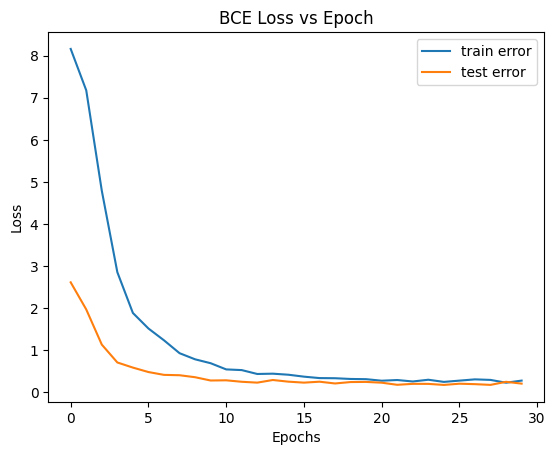

In [26]:
import matplotlib.pyplot as plt 
import numpy as np

plt.plot(epochs, train_losses, label= "train error")
plt.plot(epochs, test_losses, label= "test error")
plt.title("BCE Loss vs Epoch")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

In [27]:
import shap
features = common_utils.extract_features(r"C:\Users\kyeyo\OneDrive\Desktop\SC4001\Individual Assignment\files_PartA\files_PartA\audio_test.wav")
features.drop(labels = ["filename"], axis=1, inplace=True)
# display(features)
features = torch.tensor(features.to_numpy().astype(np.float32), dtype = torch.float)

background_data = 0
for X_batch, Y_batch in train_load:
    background_data = X_batch  
    break  # Take only the first batch

explainer = shap.DeepExplainer(model, background_data)
shap_values = explainer(features)
shap_array = shap_values.values  

# Remove singleton axes
shap_array = np.squeeze(shap_array)   # → shape: (n_features,)

# Mean absolute shap value per feature
feature_importance = np.abs(shap_array)  # absolute SHAP values

# Get top 5 indices
top5_indices = np.argsort(feature_importance)[-5:][::-1]
print("Top 5 Feature Indices:", top5_indices)

print("Top 5 SHAP Values:", feature_importance[top5_indices])

# Map to feature names
feature_names = df.columns[1:]  # ensure these match the 57 features
top5_names = [feature_names[i] for i in top5_indices]
print("Top 5 influential features:", top5_names)

Top 5 Feature Indices: [9 7 5 8 4]
Top 5 SHAP Values: [0.40476352 0.08182067 0.05528307 0.00801922 0.00435503]
Top 5 influential features: ['rolloff_var', 'spectral_bandwidth_var', 'spectral_centroid_var', 'rolloff_mean', 'spectral_centroid_mean']


# Q2

In [110]:
no_folds = 5
lr_list = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
batch_size = 128

In [205]:
from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()
standard_scaler = preprocessing.StandardScaler()

df_cpy = df.copy()
df_cpy = df.sample(frac=1).reset_index(drop=True)
df_cpy['label'] = label_encoder.fit_transform(df_cpy['label'])
nd_X = df_cpy.drop(["filename", "label"], axis = 1).to_numpy()
nd_Y = df_cpy["label"].to_numpy().reshape(-1, 1)
nd_X = standard_scaler.fit_transform(nd_X)

dataloader_A2 = DataLoader(common_utils.AudioDataset(nd_X,
    torch.tensor(nd_Y.reshape(-1, 1), dtype=torch.float32))
    , batch_size = 128)

In [209]:
from sklearn.metrics import roc_auc_score
import time

def create_folds(X, Y, no_folds):
    X_folds = np.array_split(X, no_folds)
    Y_folds = np.array_split(Y, no_folds)
    return X_folds, Y_folds

def get_train_test_split(X_folds, Y_folds, fold, no_folds):
    x_test, y_test = X_folds[fold].detach().numpy(), Y_folds[fold].detach().numpy()
    x_train = np.concatenate([X_folds[i] for i in range(no_folds) if i != fold], axis=0)
    y_train = np.concatenate([Y_folds[i] for i in range(no_folds) if i != fold], axis=0)
    return x_train, y_train, x_test, y_test

def train_one_fold(x_train, y_train, x_test, y_test, lr, max_epoch):
    model = common_utils.MLP()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    early_stopper = common_utils.EarlyStopper()

    x_train_tensor = torch.tensor(x_train, dtype=torch.float)
    y_train_tensor = torch.tensor(y_train, dtype=torch.float)
    x_test_tensor = torch.tensor(x_test, dtype=torch.float)
    y_test_tensor = torch.tensor(y_test, dtype=torch.float)

    epoch = 0
    train_loss = 0.0
    test_loss = 0.0
    pred_train = torch.tensor([])
    pred_test = torch.tensor([])

    for epoch in range(max_epoch):
        model.train()
        optimizer.zero_grad()
        pred_train = model(x_train_tensor)
        train_loss = loss_fn(pred_train, y_train_tensor).item()
        loss_fn(pred_train, y_train_tensor).backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            pred_test = model(x_test_tensor)
            test_loss = loss_fn(pred_test, y_test_tensor).item()

        if early_stopper.early_stop(test_loss):
            break

    return epoch, train_loss, test_loss, pred_train.detach().numpy().ravel(), pred_test.detach().numpy().ravel()

def record_performance(performance, fold, lr_idx, epoch, train_loss, test_loss, pred_train_prob, pred_test_prob, y_train, y_test):
    pred_train_np = (pred_train_prob >= 0.5).astype(int)
    pred_test_np = (pred_test_prob >= 0.5).astype(int)

    # Train metrics
    performance[fold, lr_idx, 0, 0] = train_loss
    performance[fold, lr_idx, 0, 1] = safe_auc(y_train.ravel(), pred_train_prob)
    performance[fold, lr_idx, 0, 3] = epoch
    performance[fold, lr_idx, 0, 4] = np.mean(pred_train_np == y_train.ravel())

    # Test metrics
    performance[fold, lr_idx, 1, 0] = test_loss
    performance[fold, lr_idx, 1, 1] = safe_auc(y_test.ravel(), pred_test_prob)
    performance[fold, lr_idx, 1, 3] = epoch
    performance[fold, lr_idx, 1, 4] = np.mean(pred_test_np == y_test.ravel())

def safe_auc(y_true, y_prob):
    try:
        return roc_auc_score(y_true, y_prob)
    except:
        return np.nan

def train(X, Y, lr_list):
    performance = np.zeros((5, len(lr_list), 2, 5), dtype=np.float64)
    X_Y = np.zeros([5, len(lr_list), 2, 3], dtype=object)

    for lr_idx, lr in enumerate(lr_list):
        t_start = time.time()

        # Initialize accumulators across batches
        fold_accum = {fold: {"x_train": [], "y_train": [], "pred_train": [],
                            "x_test": [], "y_test": [], "pred_test": []}
                    for fold in range(no_folds)}
        
        for X, Y in dataloader_A2:
            X_folds, Y_folds = create_folds(X, Y, no_folds)
            for fold in range(no_folds):
                x_train, y_train, x_test, y_test = get_train_test_split(X_folds, Y_folds, fold, no_folds)

                epoch, train_loss, test_loss, pred_train_prob, pred_test_prob = train_one_fold(
                    x_train, y_train, x_test, y_test, lr, max_epoch
                )

                record_performance(performance, fold, lr_idx, epoch, train_loss, test_loss, pred_train_prob, pred_test_prob, y_train, y_test)

                fold_accum[fold]["x_train"].append(x_train)
                fold_accum[fold]["y_train"].append(y_train.reshape(-1))
                fold_accum[fold]["pred_train"].append(pred_train_prob.reshape(-1))
                fold_accum[fold]["x_test"].append(x_test)
                fold_accum[fold]["y_test"].append(y_test.reshape(-1))
                fold_accum[fold]["pred_test"].append(pred_test_prob.reshape(-1))

        t_end = time.time()
        for fold in range(no_folds):
            X_Y[fold, lr_idx, 0, 0] = np.vstack(fold_accum[fold]["x_train"])
            X_Y[fold, lr_idx, 0, 1] = np.hstack(fold_accum[fold]["y_train"])
            X_Y[fold, lr_idx, 0, 2] = np.hstack(fold_accum[fold]["pred_train"])
            X_Y[fold, lr_idx, 1, 0] = np.vstack(fold_accum[fold]["x_test"])
            X_Y[fold, lr_idx, 1, 1] = np.hstack(fold_accum[fold]["y_test"])
            X_Y[fold, lr_idx, 1, 2] = np.hstack(fold_accum[fold]["pred_test"])
            for _ in range(2):
                performance[fold, lr_idx, _, 2] = t_end - t_start

    return performance, X_Y

In [216]:
for lr_idx, lr in enumerate(lr_list):
    print("lr", lr)
    for f in range(no_folds):
        x = X_Y[f, lr_idx, 0, 0]
        y = X_Y[f, lr_idx, 0, 1]
        print("\tfold", f, "x.shape", getattr(x, "shape", None), "y.shape", getattr(y, "shape", None))


lr 0.0001
	fold 0 x.shape (1594, 57) y.shape (1594,)
	fold 1 x.shape (1594, 57) y.shape (1594,)
	fold 2 x.shape (1594, 57) y.shape (1594,)
	fold 3 x.shape (1609, 57) y.shape (1609,)
	fold 4 x.shape (1609, 57) y.shape (1609,)
lr 0.0005
	fold 0 x.shape (1594, 57) y.shape (1594,)
	fold 1 x.shape (1594, 57) y.shape (1594,)
	fold 2 x.shape (1594, 57) y.shape (1594,)
	fold 3 x.shape (1609, 57) y.shape (1609,)
	fold 4 x.shape (1609, 57) y.shape (1609,)
lr 0.001
	fold 0 x.shape (1594, 57) y.shape (1594,)
	fold 1 x.shape (1594, 57) y.shape (1594,)
	fold 2 x.shape (1594, 57) y.shape (1594,)
	fold 3 x.shape (1609, 57) y.shape (1609,)
	fold 4 x.shape (1609, 57) y.shape (1609,)
lr 0.005
	fold 0 x.shape (1594, 57) y.shape (1594,)
	fold 1 x.shape (1594, 57) y.shape (1594,)
	fold 2 x.shape (1594, 57) y.shape (1594,)
	fold 3 x.shape (1609, 57) y.shape (1609,)
	fold 4 x.shape (1609, 57) y.shape (1609,)
lr 0.01
	fold 0 x.shape (1594, 57) y.shape (1594,)
	fold 1 x.shape (1594, 57) y.shape (1594,)
	fold 2 

In [217]:
performance, X_Y = train(nd_X, nd_Y, lr_list)

# use these dicts for fincal product
# # initialize dicts
# X_train_scaled_dict, X_val_scaled_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
# for lr_idx, lr in enumerate(lr_list):
#     X_train_scaled_dict[lr] = [X_Y[f, lr_idx, 0, 0] for f in range(no_folds)]
#     X_val_scaled_dict[lr]   = [X_Y[f, lr_idx, 1, 0] for f in range(no_folds)]
#     y_train_dict[lr]        = [X_Y[f, lr_idx, 0, 1].reshape(-1) for f in range(no_folds)]
#     y_val_dict[lr]          = [X_Y[f, lr_idx, 1, 1].reshape(-1) for f in range(no_folds)]

performance shape: (5, 5, 2, 5)
lr	mean_acc	mean_auc
0.0001	0.4125	0.5097
0.0005	0.4500	0.4543
0.001	0.5750	0.5763
0.005	0.4750	0.7780
0.01	0.6000	0.8718


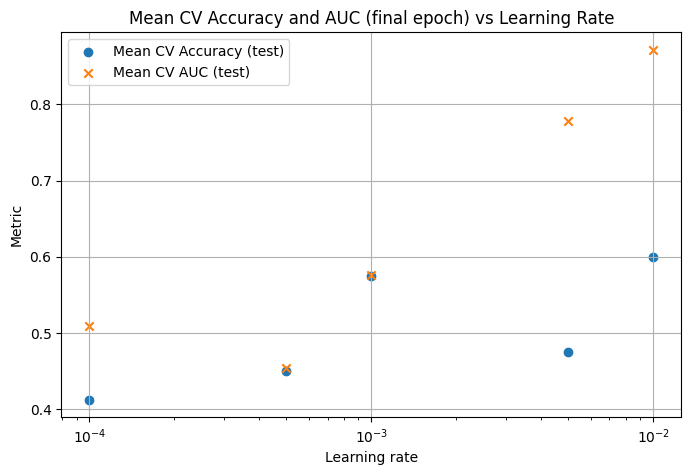

In [218]:
# Aggregate mean CV accuracy and mean CV AUC (final epoch) across folds, then plot vs learning rate
import matplotlib.pyplot as plt
import numpy as np
# 4 due to track loss, auc, time, final epoch (for graphing)
# metric indices used in train(): LOSS=0, AUC=1, TIME=2, EPOCH=3, ACC=4
LOSS_IDX, AUC_IDX, TIME_IDX, EPOCH_IDX, ACC_IDX = 0, 1, 2, 3, 4

# performance expected shape: (no_folds, len(lr_list), 2, 5)
print('performance shape:', performance.shape)

# take metrics from the test split (index 1)
mean_accs = np.nanmean(performance[:, :, 1, ACC_IDX], axis=0)
mean_aucs = np.nanmean(performance[:, :, 1, AUC_IDX], axis=0)

# Print a small summary table
print('lr\tmean_acc\tmean_auc')
for lr, a, auc in zip(lr_list, mean_accs, mean_aucs):
    print(f"{lr}\t{a:.4f}\t{auc:.4f}")

# Scatter plot
plt.figure(figsize=(8,5))
plt.scatter(lr_list, mean_accs, label='Mean CV Accuracy (test)', marker='o')
plt.scatter(lr_list, mean_aucs, label='Mean CV AUC (test)', marker='x')
plt.xscale('log')
plt.xlabel('Learning rate')
plt.ylabel('Metric')
plt.title('Mean CV Accuracy and AUC (final epoch) vs Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

In [219]:
# Compute mean last-epoch training time vs learning rate and produce confusion matrix for chosen lr
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def compute_mean_metrics(performance, lr_list):
    TIME_IDX, ACC_IDX = 2, 4

    mean_times = np.nanmean(performance[:, :, 0, TIME_IDX], axis=0)
    mean_accs = np.nanmean(performance[:, :, 1, ACC_IDX], axis=0)

    time_table = pd.DataFrame({
        'learning_rate': lr_list,
        'mean_last_epoch_time_s': mean_times,
        'mean_test_acc': mean_accs
    })

    return time_table

def select_optimal_lr(time_table):
    best_idx = np.nanargmax(time_table['mean_test_acc'].values)
    ties = np.where(np.isclose(time_table['mean_test_acc'].values,
                               time_table['mean_test_acc'].values[best_idx]))[0]
    if len(ties) > 1:
        best_idx = ties[np.argmin(time_table['mean_last_epoch_time_s'].values[ties])]
    return best_idx, time_table.loc[best_idx, 'learning_rate']

time_table = compute_mean_metrics(performance, lr_list)
display(time_table)
best_idx, optimal_lr = select_optimal_lr(time_table)
print(f"Selected optimal learning rate: {optimal_lr}")

optim_performance, X_Y = train(nd_X, nd_Y, [optimal_lr])

,learning_rate,mean_last_epoch_time_s,mean_test_acc
0,0.0001,12.856166,0.4125
1,0.0005,15.399739,0.4500
2,0.0010,13.871172,0.5750
3,0.0050,10.159448,0.4750
4,0.0100,9.945997,0.6000


Selected optimal learning rate: 0.01


<function __main__.compute_mean_metrics(performance, lr_list)>

In [223]:
                # X_Y[fold, lr_idx, 0, 0] = x_train
                # X_Y[fold, lr_idx, 0, 1] = y_train
                # X_Y[fold, lr_idx, 1, 0] = x_test
                # X_Y[fold, lr_idx, 1, 1] = y_test
print(X_Y[0, 0, 0, 2])

[0.5048978  0.4958145  0.49733752 ... 0.5002958  0.5073564  0.5112761 ]


In [ ]:
# print(X_Y[0, 0, 0, 1])
# Build true labels and predicted probabilities across folds
Y = np.concatenate([X_Y[fold, 0, 1, 1] for fold in range(no_folds)], axis=0).ravel().astype(int)
pred_probs = np.concatenate([X_Y[fold, 0, 1, 2] for fold in range(no_folds)], axis=0).ravel()
# Threshold probabilities at 0.5 to obtain class predictions
pred = (pred_probs >= 0.5).astype(int)

# Optional quick sanity prints
print('Y shape:', Y.shape, 'pred_probs shape:', pred_probs.shape, 'pred shape:', pred.shape)

Confusion matrix for selected configuration:
[[1000    0]
 [1000    0]]


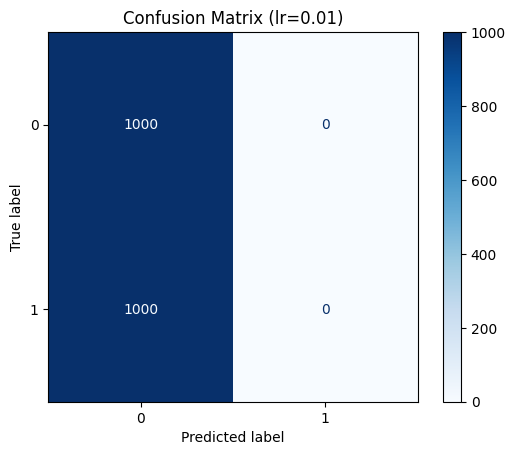


Selection reason:
Selected learning rate 0.01 because it achieved the highest mean test accuracy across folds (mean test acc = 0.6000). When there was a tie in accuracy, the learning rate with lower mean training time was chosen.


In [222]:
cm = confusion_matrix(Y, pred)
print('Confusion matrix for selected configuration:')
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix (lr={optimal_lr})')
plt.show()

# Reason for selection
reason = (
    f"Selected learning rate {optimal_lr} because it achieved the highest mean test accuracy "
    f"across folds (mean test acc = {time_table.loc[best_idx, 'mean_test_acc']:.4f}). "
    "When there was a tie in accuracy, the learning rate with lower mean training time was chosen."
)
print('\nSelection reason:')
print(reason)
